# ❄️ Hypothese 1: Lohnt sich der Winterkauf?
**EDA King County House Sales** · Kunde: **Thomas Hansen** · einfache Version

| # | Schritt (nach `02_workflow`) |
|---|---|
| 1 | Kunde, Forschungsfrage & Hypothese |
| 2 | Daten verstehen |
| 3 | Daten bereinigen |
| 4 | Daten erkunden |
| 5 | Zusammenhänge |
| 6 | Hypothese prüfen |
| 7 | Folgefrage: Liegt es an der Jahreszeit oder an der Lage? |
| 8 | Fancy Visual: die Preis-Jahresuhr |
| 9 | Erkenntnisse & Empfehlungen |

---
## 1 · Kunde, Forschungsfrage & Hypothese
**Thomas Hansen** (Käufer): 5 Kinder, wenig Geld, möchte eine schöne Nachbarschaft. Offene Fragen aus der Aufgabenstellung: *Zeitpunkt? Lage?*

| Frage | Hypothese | Indikatoren |
|---|---|---|
| Spart Thomas Geld, wenn er im Winter kauft? | Bei Häusern mit **≥ 4 Schlafzimmern** liegt der **Median-Preis im Winter (Nov–Feb)** um **mindestens 5 %** unter dem Median im **Restjahr (Mär–Okt)**. | `date`, `price`, `bedrooms` |

**Annahmen (ausdrücklich, wie in `01_assignment` verlangt):**
* **Großes Haus** = mindestens 4 Schlafzimmer (7 Personen).
* **Winter** = November bis Februar, weil dann erfahrungsgemäß weniger Käufer unterwegs sind.
* **5 %** ist die Schwelle, ab der sich das Warten lohnt: Bei ~575.000 $ sind das rund 29.000 $, etwa die Kaufnebenkosten.
* Wir vergleichen **Mediane**, weil Hauspreise stark schief verteilt sind und einzelne Villen den Mittelwert verzerren.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["text.parse_math"] = False  # "$" ist hier Währung, keine Formel
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
Path("output").mkdir(exist_ok=True)

---
## 2 · Daten verstehen

In [13]:
# Die Rohdaten wurden in 03_fetching_the_data_eda per SQL (JOIN der beiden Tabellen im Schema eda) geholt
# und in 04_eda.ipynb bereinigt (33 → 3 Schlafzimmer, yr_renovated / 10, fehlende Werte, sqft → qm).
df = pd.read_csv("data/eda_tk_cleaned.csv", parse_dates=["date"])
print("Zeilen, Spalten:", df.shape)
print("Zeitraum:", df["date"].min().date(), "bis", df["date"].max().date())
df.head()

Zeilen, Spalten: (21597, 26)
Zeitraum: 2014-05-02 bis 2015-05-27


,sale_id,house_id,date,price,bedrooms,bathrooms,qm_living,qm_lot,floors,waterfront,...,yr_renovated,zipcode,lat,long,qm_living15,qm_lot15,yr_renovated_unbekannt,keller_typ,preis_pro_qm_wohnflaeche,preis_pro_qm_grundstueck
0,1,7129300520,2014-10-13,"221,900.00",3,1.00,109.63,524.90,1.00,0,...,0,98178,47.51,-122.26,124.49,524.90,False,Kein Keller (0 qm),"2,024.08",422.75
1,2,6414100192,2014-12-09,"538,000.00",3,2.25,238.76,672.80,2.00,0,...,1991,98125,47.72,-122.32,157.01,709.69,False,Nutzbarer Keller (>= 5 qm),"2,253.31",799.64
2,3,5631500400,2015-02-25,"180,000.00",2,1.00,71.54,929.03,1.00,0,...,0,98028,47.74,-122.23,252.70,748.98,True,Kein Keller (0 qm),"2,516.07",193.75
3,4,2487200875,2014-12-09,"604,000.00",4,3.00,182.09,464.52,1.00,0,...,0,98136,47.52,-122.39,126.35,464.52,False,Nutzbarer Keller (>= 5 qm),"3,317.04","1,300.27"
4,5,1954400510,2015-02-18,"510,000.00",3,2.00,156.08,750.66,1.00,0,...,0,98074,47.62,-122.05,167.23,697.05,False,Kein Keller (0 qm),"3,267.56",679.40


In [14]:
# Nur die Spalten, die wir für H1 brauchen
spalten = ["date", "price", "bedrooms", "qm_living", "grade", "zipcode"]
print(df[spalten].dtypes, "\n")
print("Fehlende Werte je Spalte:\n", df[spalten].isna().sum())
df[spalten].describe()

date         datetime64[us]
price               float64
bedrooms              int64
qm_living           float64
grade                 int64
zipcode               int64
dtype: object 

Fehlende Werte je Spalte:
 date         0
price        0
bedrooms     0
qm_living    0
grade        0
zipcode      0
dtype: int64


,date,price,bedrooms,qm_living,grade,zipcode
count,21597,"21,597.00","21,597.00","21,597.00","21,597.00","21,597.00"
mean,2014-10-29 04:20:38.171968,"540,296.57",3.37,193.27,7.66,"98,077.95"
min,2014-05-02 00:00:00,"78,000.00",1.00,34.37,3.00,"98,001.00"
25%,2014-07-22 00:00:00,"322,000.00",3.00,132.85,7.00,"98,033.00"
50%,2014-10-16 00:00:00,"450,000.00",3.00,177.44,7.00,"98,065.00"
75%,2015-02-17 00:00:00,"645,000.00",4.00,236.90,8.00,"98,118.00"
max,2015-05-27 00:00:00,"7,700,000.00",11.00,"1,257.91",13.00,"98,199.00"
std,NaN,"367,368.14",0.90,85.29,1.17,53.51


**Was sehen wir?**
* 21.597 Verkäufe von Mai 2014 bis Mai 2015, also **13 Monate und genau ein Winter**.
* **Keine fehlenden Werte** in den relevanten Spalten.
* **Stetig:** `price`, `qm_living`. **Kategorial/diskret:** `bedrooms`, `grade`, `zipcode`. Das Datum zerlegen wir gleich in Monat und Saison.
* Der Preis ist stark schief: Der Mittelwert (540.000 $) liegt deutlich über dem Median (450.000 $).

---
## 3 · Daten bereinigen
Die eigentliche Bereinigung ist schon in `04_eda.ipynb` passiert. Hier machen wir nur noch drei Dinge:
1. **Neue Merkmale** aus dem Datum: Monat und Saison (Winter / Restjahr).
2. **Zielgruppe filtern:** nur Häuser mit ≥ 4 Schlafzimmern.
3. **Ausreißer prüfen** und entscheiden, ob wir sie entfernen.

Häuser mit ≥ 4 Schlafzimmern: 8,816 von 21,597 Verkäufen


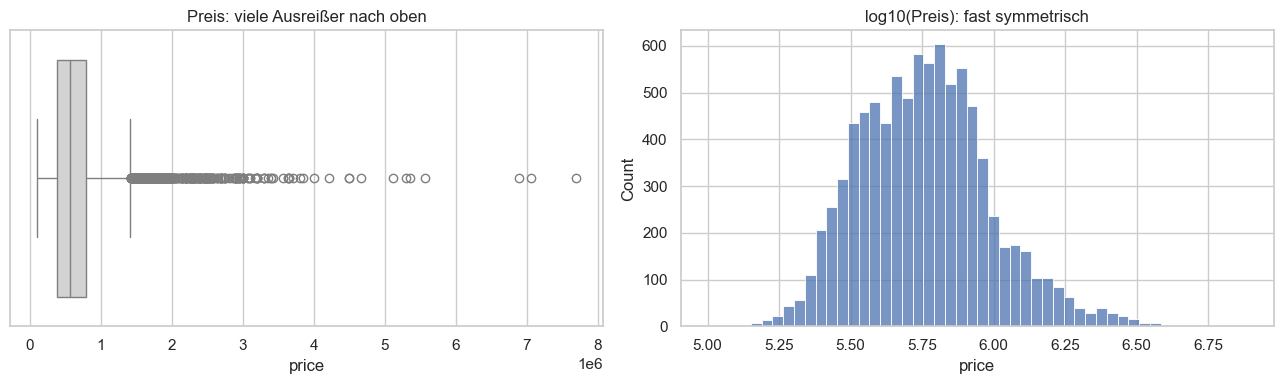

Verworfene Zeilen: 0 (Ausreißer bleiben drin, der Median ist robust gegen sie)


In [15]:
df["monat"] = df["date"].dt.month
df["winter"] = df["monat"].isin([11, 12, 1, 2])
df["saison"] = np.where(df["winter"], "Winter (Nov–Feb)", "Restjahr (Mär–Okt)")

gross = df[df["bedrooms"] >= 4].copy()
print(f"Häuser mit ≥ 4 Schlafzimmern: {len(gross):,} von {len(df):,} Verkäufen")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x=gross["price"], ax=axes[0], color="lightgray")
axes[0].set_title("Preis: viele Ausreißer nach oben")
sns.histplot(np.log10(gross["price"]), bins=50, ax=axes[1])
axes[1].set_title("log10(Preis): fast symmetrisch")
plt.tight_layout()
plt.show()

print("Verworfene Zeilen: 0 (Ausreißer bleiben drin, der Median ist robust gegen sie)")

**Entscheidung:** Der Boxplot zeigt viele teure Ausreißer, das sind aber echte Verkäufe (Villen) und keine Fehler. Da wir **Mediane** vergleichen, stören sie nicht, also **entfernen wir nichts**. Für Diagramme nutzen wir eine **log-Skala**, damit die Verteilung lesbar wird.

---
## 4 · Daten erkunden

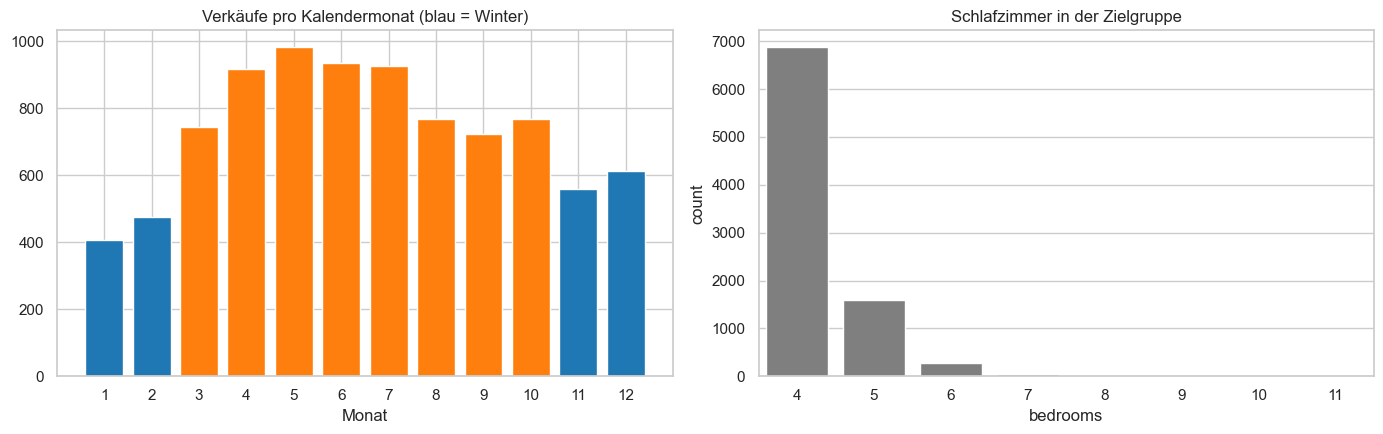

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Wie viele Häuser werden pro Monat verkauft?
verkaeufe = gross.groupby("monat").size()
axes[0].bar(verkaeufe.index, verkaeufe.values,
            color=["tab:blue" if m in [11, 12, 1, 2] else "tab:orange" for m in verkaeufe.index])
axes[0].set_xticks(range(1, 13))
axes[0].set_title("Verkäufe pro Kalendermonat (blau = Winter)")
axes[0].set_xlabel("Monat")

# Wie viele Schlafzimmer haben die großen Häuser?
sns.countplot(x="bedrooms", data=gross, ax=axes[1], color="tab:gray")
axes[1].set_title("Schlafzimmer in der Zielgruppe")
plt.tight_layout()
plt.show()

**Was sehen wir?**
* Im Winter werden **deutlich weniger** Häuser verkauft (Januar nur ~400, Mai fast 1.000). Weniger Nachfrage spricht erst einmal für niedrigere Preise.
* Die Zielgruppe besteht zum Großteil aus Häusern mit 4 Schlafzimmern, 5+ ist selten.

---
## 5 · Zusammenhänge

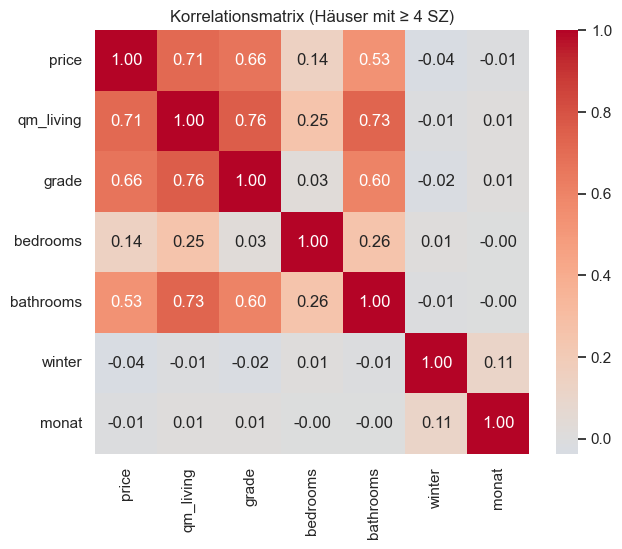

In [17]:
korr = gross[["price", "qm_living", "grade", "bedrooms", "bathrooms", "winter", "monat"]].astype(float).corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(korr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korrelationsmatrix (Häuser mit ≥ 4 SZ)")
plt.show()

**Was sehen wir?** Den Preis bestimmen vor allem **Wohnfläche** und **Bauqualität (grade)** (r ≈ 0,7). `winter` korreliert mit dem Preis nur bei **≈ −0,04**: Die Jahreszeit ist im Vergleich ein sehr kleiner Faktor. Klein heißt aber nicht null, deshalb schauen wir genauer hin.

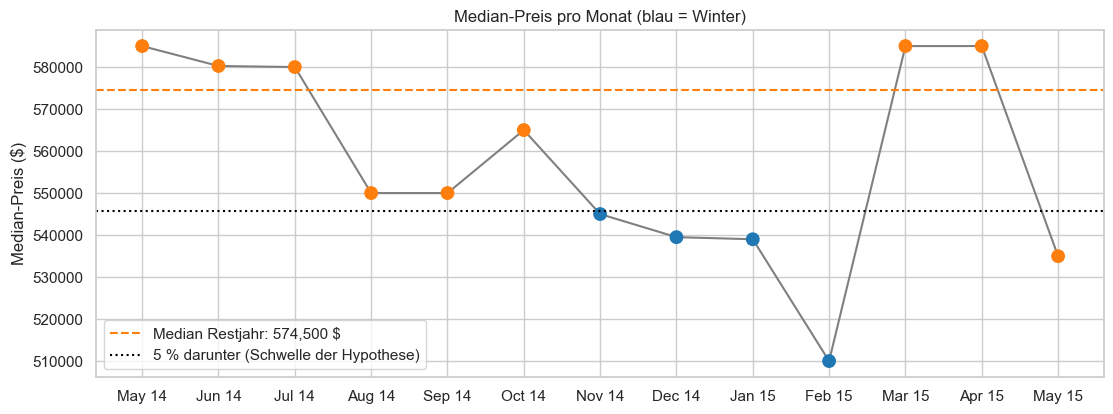

In [18]:
# Median-Preis pro Monat, chronologisch (13 Monate)
pro_monat = gross.groupby(gross["date"].dt.to_period("M"))["price"].median()
median_rest = gross.loc[~gross["winter"], "price"].median()

fig, ax = plt.subplots(figsize=(13, 4.5))
farben = ["tab:blue" if p.month in [11, 12, 1, 2] else "tab:orange" for p in pro_monat.index]
ax.plot(pro_monat.index.strftime("%b %y"), pro_monat.values, color="gray", zorder=1)
ax.scatter(pro_monat.index.strftime("%b %y"), pro_monat.values, c=farben, s=80, zorder=2)
ax.axhline(median_rest, ls="--", color="tab:orange", label=f"Median Restjahr: {median_rest:,.0f} $")
ax.axhline(median_rest * 0.95, ls=":", color="black", label="5 % darunter (Schwelle der Hypothese)")
ax.set_title("Median-Preis pro Monat (blau = Winter)")
ax.set_ylabel("Median-Preis ($)")
ax.legend()
plt.show()

**Was sehen wir?** Alle vier Wintermonate liegen **an oder unter der 5-%-Linie**, am günstigsten ist der **Februar**. Ab März springen die Preise sofort wieder hoch. Aber auch August/September 2014 und Mai 2015 sind schon niedrig: Die Monatswerte schwanken stark. Ob der Unterschied belastbar ist, prüfen wir gleich.

---
## 6 · Hypothese prüfen
Drei einfache Schritte:
1. **Kennzahl:** Um wie viel % liegt der Winter-Median unter dem Restjahr?
2. **Mann-Whitney-U-Test:** Ist der Winter *überhaupt* günstiger, oder ist das Zufall? (Rangtest, braucht keine Normalverteilung)
3. **Bootstrap:** Wir ziehen 2.000-mal neue Stichproben aus den Daten und berechnen jedes Mal die Differenz. So sehen wir, **wie sicher die 5 % sind**.

In [19]:
winter = gross.loc[gross["winter"], "price"]
rest = gross.loc[~gross["winter"], "price"]
diff = 100 * (winter.median() / rest.median() - 1)

p_wert = stats.mannwhitneyu(winter, rest, alternative="less").pvalue

rng = np.random.default_rng(42)
boot = np.array([
    100 * (np.median(rng.choice(winter, len(winter))) / np.median(rng.choice(rest, len(rest))) - 1)
    for _ in range(2000)
])
obere_grenze = np.percentile(boot, 95)   # mit 95 % Sicherheit ist der Abschlag mindestens so groß

print(f"Median Winter:   {winter.median():>10,.0f} $  (n = {len(winter):,})")
print(f"Median Restjahr: {rest.median():>10,.0f} $  (n = {len(rest):,})")
print(f"Differenz:       {diff:>10.1f} %")
print(f"Mann-Whitney p:  {p_wert:.1e}  → Winter ist {'signifikant' if p_wert < 0.05 else 'nicht signifikant'} günstiger")
print(f"Bootstrap: mit 95 % Sicherheit mindestens {abs(obere_grenze):.1f} % günstiger")
print(f"Anteil der Ziehungen mit ≥ 5 % Abschlag: {np.mean(boot <= -5):.0%} (nötig wären 95 %)")

Median Winter:      534,000 $  (n = 2,055)
Median Restjahr:    574,500 $  (n = 6,761)
Differenz:             -7.0 %
Mann-Whitney p:  2.1e-06  → Winter ist signifikant günstiger
Bootstrap: mit 95 % Sicherheit mindestens 4.0 % günstiger
Anteil der Ziehungen mit ≥ 5 % Abschlag: 87% (nötig wären 95 %)


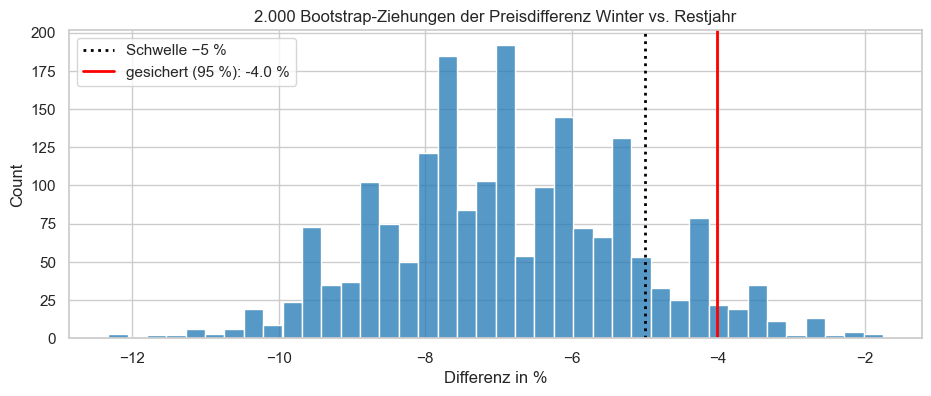

In [20]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.histplot(boot, bins=40, ax=ax, color="tab:blue")
ax.axvline(-5, color="black", ls=":", lw=2, label="Schwelle −5 %")
ax.axvline(obere_grenze, color="red", lw=2, label=f"gesichert (95 %): {obere_grenze:.1f} %")
ax.set_title("2.000 Bootstrap-Ziehungen der Preisdifferenz Winter vs. Restjahr")
ax.set_xlabel("Differenz in %")
ax.legend()
plt.show()

**Ergebnis:**
* Der Winter ist **sicher günstiger** (p weit unter 0,05), im Median um rund **7 %**.
* Aber die rote Linie liegt **rechts** der −5-%-Linie: Mit 95 % Sicherheit lassen sich nur **rund 4 %** belegen. Etwa jede achte Ziehung liegt unter 5 %.
* **→ H1 ist nicht bestätigt.** Die Richtung stimmt, die 5 % sind aber nicht gesichert.

---
## 7 · Folgefrage: Liegt es an der Jahreszeit oder an der Lage?
Vielleicht wurden im Winter einfach **kleinere Häuser** oder Häuser in **günstigeren Postleitzahlen** verkauft? Das prüfen wir mit zwei einfachen Vergleichen:
* **Preis pro qm** statt Gesamtpreis, damit die Hausgröße herausgerechnet ist.
* **Innerhalb derselben PLZ:** Für jede PLZ mit genug Verkäufen (≥ 10 je Saison) berechnen wir die Differenz und nehmen davon den Median.

                    qm_living  grade  bedrooms
saison                                        
Restjahr (Mär–Okt)     233.19   8.00      4.00
Winter (Nov–Feb)       232.26   8.00      4.00 

Gesamtpreis (roh)              -7.00
Preis pro qm                   -4.60
pro qm, gleiche PLZ (63 PLZ)   -1.10
dtype: float64


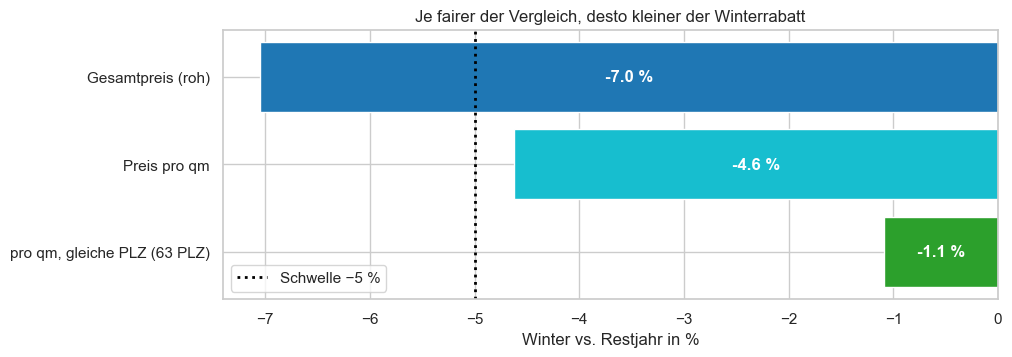

In [21]:
# Unterscheiden sich die Häuser?
print(gross.groupby("saison")[["qm_living", "grade", "bedrooms"]].median(), "\n")

# 1) Preis pro qm
qm_w = gross.loc[gross["winter"], "preis_pro_qm_wohnflaeche"].median()
qm_r = gross.loc[~gross["winter"], "preis_pro_qm_wohnflaeche"].median()
diff_qm = 100 * (qm_w / qm_r - 1)

# 2) innerhalb derselben PLZ (Preis pro qm)
plz = gross.groupby(["zipcode", "winter"])["preis_pro_qm_wohnflaeche"].agg(["median", "size"]).unstack()
plz = plz[(plz["size"] >= 10).all(axis=1)]
plz_diff = 100 * (plz["median"][True] / plz["median"][False] - 1)
diff_plz = plz_diff.median()

stufen = pd.Series({"Gesamtpreis (roh)": diff, "Preis pro qm": diff_qm,
                    f"pro qm, gleiche PLZ ({len(plz_diff)} PLZ)": diff_plz})
print(stufen.round(1))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(stufen.index[::-1], stufen.values[::-1], color=["tab:green", "tab:cyan", "tab:blue"])
ax.axvline(-5, color="black", ls=":", lw=2, label="Schwelle −5 %")
for i, v in enumerate(stufen.values[::-1]):
    ax.text(v / 2, i, f"{v:.1f} %", va="center", ha="center", color="white", weight="bold")
ax.set_xlabel("Winter vs. Restjahr in %")
ax.set_title("Je fairer der Vergleich, desto kleiner der Winterrabatt")
ax.legend()
plt.show()

**Was sehen wir?** Die Häuser selbst sind gleich (gleiche Fläche, gleicher Grade). Rechnet man aber Größe und Lage heraus, **schrumpft der Rabatt von 7 % auf nur noch ~1–2 %**. Ein großer Teil des „Winterrabatts“ kommt daher, dass im Winter anteilig mehr Häuser in **günstigeren Gegenden** verkauft wurden.

---
## 8 · Fancy Visual: die Preis-Jahresuhr
Jeder Monat ist eine Stunde auf der Uhr. Der Abstand zur Mitte zeigt den Median-Preis als **Index (Restjahr = 100)**. Der gestrichelte Ring bei **95** ist die Schwelle der Hypothese. Mit der Maus sieht man Preis und Anzahl Verkäufe (interaktiv, auch als HTML in `output/`).

In [22]:
monate = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
uhr = gross.groupby("monat")["price"].agg(["median", "size"]).reset_index()
uhr["index"] = 100 * uhr["median"] / median_rest
uhr["name"] = [monate[m - 1] for m in uhr["monat"]]
uhr = pd.concat([uhr, uhr.iloc[[0]]])  # Kreis schließen

fig = go.Figure()
fig.add_trace(go.Scatterpolar(r=[100] * 13, theta=uhr["name"], mode="lines", name="Restjahr = 100",
                              line=dict(color="#eb6834", dash="dash")))
fig.add_trace(go.Scatterpolar(r=[95] * 13, theta=uhr["name"], mode="lines", name="−5 % (Hypothese)",
                              line=dict(color="black", dash="dot")))
fig.add_trace(go.Scatterpolar(
    r=uhr["index"], theta=uhr["name"], mode="lines+markers", fill="toself", name="Median-Preis (Index)",
    line=dict(color="#2a78d6", width=3), fillcolor="rgba(42,120,214,0.15)",
    marker=dict(size=12, color=["#2a78d6" if m in [11, 12, 1, 2] else "#eb6834" for m in uhr["monat"]]),
    customdata=np.stack([uhr["median"], uhr["size"]], axis=-1),
    hovertemplate="<b>%{theta}</b><br>Index %{r:.1f}<br>Median %{customdata[0]:,.0f} $<br>%{customdata[1]} Verkäufe<extra></extra>",
))
fig.update_layout(
    title="Preis-Jahresuhr: Häuser mit ≥ 4 Schlafzimmern (blau = Winter)",
    polar=dict(radialaxis=dict(range=[85, 108]), angularaxis=dict(direction="clockwise", rotation=90)),
    height=600, template="plotly_white",
)
fig.write_html("output/h1_easy_jahresuhr.html")
fig.show()

**Was sehen wir?** Die Uhr ist im Winter (November bis Februar) nach innen „eingedellt“: Alle vier Wintermonate liegen am oder innerhalb des 95er-Rings, der **Februar** am tiefsten. Im Frühling (März–Juli) liegen die Preise am höchsten. Die Delle ist sichtbar, aber nicht groß. Das passt zum Testergebnis: Der Rabatt ist echt, die 5 % sind aber nicht gesichert.

---
## 9 · Erkenntnisse & Empfehlungen

### Ergebnis
| | |
|---|---|
| Hypothese | Winter mind. 5 % günstiger (≥ 4 SZ) |
| Beobachtet | **−7 %** im Median, signifikant |
| Mit 95 % Sicherheit | nur **≈ −4 %** |
| Bei gleicher Größe & Lage | nur noch **≈ −1 bis −2 %** |
| **Urteil** | **✗ H1 nicht bestätigt**: Die Richtung stimmt, die Höhe nicht. |

### Erkenntnisse
1. **Im Winter wird weniger verkauft und billiger.** Große Häuser kosten im Winter im Median rund 7 % weniger, am tiefsten liegt der Februar.
2. **Die 5 % sind nicht sicher.** Statistisch gesichert sind nur etwa 4 %.
3. **Der größte Teil des Rabatts ist ein Lageeffekt.** Vergleicht man gleich große Häuser in derselben PLZ, bleiben nur 1–2 %.

### Empfehlungen für Thomas
1. **Mit wenig Rabatt rechnen:** Der Winter bringt eher **1–4 %** (ca. 6.000–23.000 $), nicht 5 % oder mehr. Den Rabatt als Puffer sehen, nicht fest einplanen.
2. **Wenn Winter, dann Januar/Februar:** Im Herbst suchen, Finanzierung klären und Anfang des Jahres abschließen. Ab März ist der Vorteil weg.
3. **Lage ist der größere Hebel:** Wer bei der Postleitzahl flexibel ist, spart deutlich mehr als durch das Timing (siehe Hypothese 2).

### Grenzen
Nur ein Winter (2014/15) im Datensatz · Verkaufsdatum ist das Abschlussdatum, nicht der Verhandlungszeitpunkt · Marktumfeld von 2014/15, nicht auf heute übertragbar.